In [1]:
!pip install -q rdkit

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
import pandas as pd

print ("RDKit loaded successfully! Version:", Chem.rdBase.rdkitVersion)

RDKit loaded successfully! Version: 2026.09.2


In [3]:
# Compare Native GLP-1 N-terminal fragment (His7-Ala8-Glu9) vs. Semaglutide Aib8-modified fragment
peptides = {
    "Native_GLP1_Nterm (His-Ala-Glu)": "N[C@@H](Cc1c[nH]cn1)C(=O)N[C@@H](C)C(=O)N[C@@H](CCC(=O)O)C(=O)O",
    "Semaglutide_Nterm (His-Aib-Glu)": "N[C@@H](Cc1c[nH]cn1)C(=O)NC(C)(C)C(=O)N[C@@H](CCC(=O)O)C(=O)O",
    "Danuglipron (Oral Small Molecule)": "CCn1c(CN2CCC(c3nc4cc(C(=O)O)ccc4n3C[C@@H]3CCCO3)CC2)nc2cc(F)ccc21"
}

results = []
for name, smiles in peptides.items():
    mol = Chem.MolFromSmiles(smiles)
    results.append({
        "Compound": name,
        "MolWeight (Da)": round(Descriptors.MolWt(mol), 2),
        "cLogP": round(Descriptors.MolLogP(mol), 2),
        "TPSA (Å²)": round(Descriptors.TPSA(mol), 2),
        "H-Donors": Descriptors.NumHDonors(mol),
        "H-Acceptors": Descriptors.NumHAcceptors(mol)
    })

df = pd.DataFrame(results)
display(df)


,Compound,MolWeight (Da),cLogP,TPSA (Å²),H-Donors,H-Acceptors
0,Native_GLP1_Nterm (His-Ala-Glu),355.35,-1.78,187.50,6,6
1,Semaglutide_Nterm (His-Aib-Glu),369.38,-1.39,187.50,6,6
2,Danuglipron (Oral Small Molecule),505.59,4.80,85.41,1,5


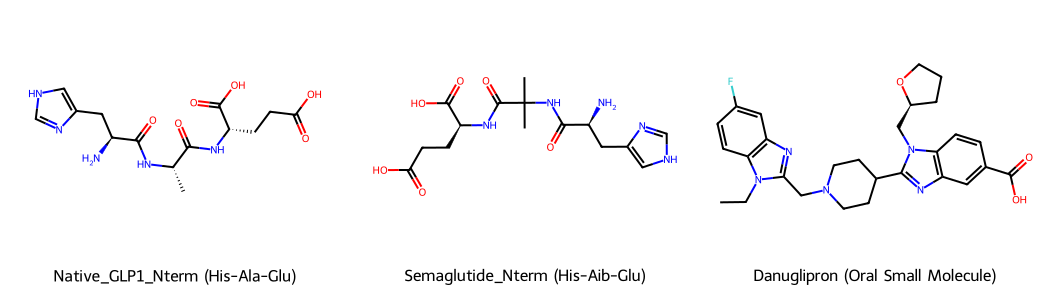

In [4]:
mols = [Chem.MolFromSmiles(s) for s in peptides.values()]
legends = list(peptides.keys())
img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(350, 300), legends=legends)
display(img)